In [52]:
import pandas as pd
import numpy as np

In [54]:
data=pd.read_csv("day_1km-towoomba.csv")

In [56]:
df = data.copy()
df["Date"] = pd.to_datetime(df["Date"])

# Drop the rows where the temperature is 0
df = df[df["MOD11A1_061_LST_Day_1km"] != 0]

# Drop 29 Feb so every year has at most 365 days
df = df[~((df["Date"].dt.month == 2) & (df["Date"].dt.day == 29))]

# Day number 1-365: in leap years, move days after Feb back by 1
after_feb_leap = df["Date"].dt.is_leap_year & (df["Date"].dt.month > 2)

new_df = pd.DataFrame({
    "Year": df["Date"].dt.year,
    "Day": df["Date"].dt.dayofyear - after_feb_leap.astype(int),
    "LST_K": df["MOD11A1_061_LST_Day_1km"],
}).reset_index(drop=True)

In [58]:
#new_df = new_df[~new_df['Year'].between(2021, 2026)]

In [60]:
new_df

,Year,Day,LST_K
0,2000,59,308.06
1,2000,60,303.24
2,2000,61,303.78
3,2000,65,312.42
4,2000,72,307.20
...,...,...,...
4327,2026,309,298.36
4328,2026,311,299.98
4329,2026,312,297.82
4330,2026,315,293.28


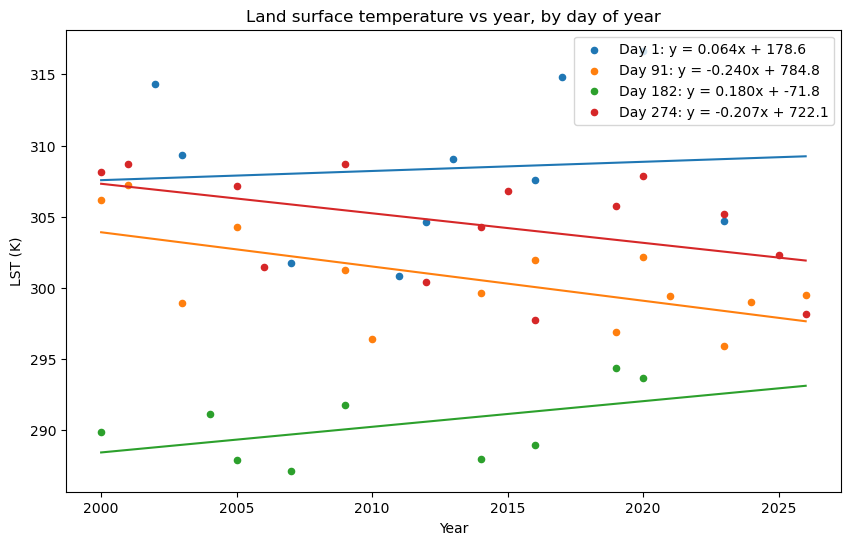

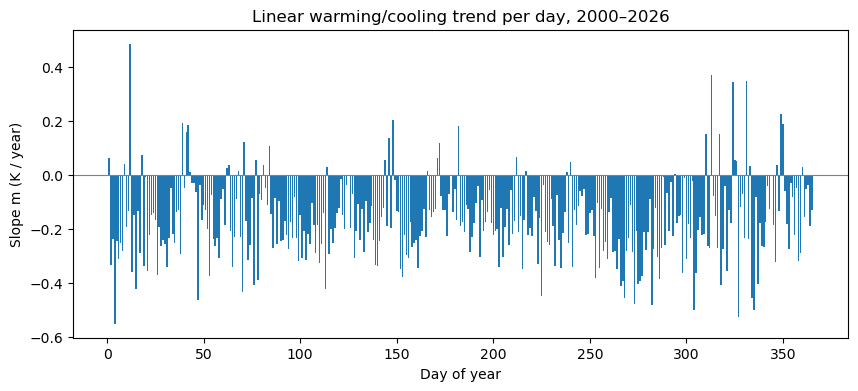

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. Fit y = mx + c for each Day ---
def fit_line(g):
    g = g.dropna(subset=["LST_K"])
    if len(g) < 2:                       # need at least 2 points for a line
        return pd.Series({"m": np.nan, "c": np.nan})
    m, c = np.polyfit(g["Year"], g["LST_K"], 1)
    return pd.Series({"m": m, "c": c})

coefs = new_df.groupby("Day")[["Year", "LST_K"]].apply(fit_line).reset_index()

# Add m and c to every row (drop old ones first so re-running doesn't duplicate)
new_df = new_df.drop(columns=["m", "c", "equation"], errors="ignore")
new_df = new_df.merge(coefs, on="Day", how="left")
new_df["equation"] = "y = " + new_df["m"].round(4).astype(str) + "x + " + new_df["c"].round(2).astype(str)

# --- 2. Plot temperature vs year for a few chosen days ---
days_to_plot = [1, 91, 182, 274]          # change to whichever days you want
fig, ax = plt.subplots(figsize=(10, 6))
years = np.arange(new_df["Year"].min(), new_df["Year"].max() + 1)

for d in days_to_plot:
    sub = new_df[new_df["Day"] == d]
    m, c = sub["m"].iloc[0], sub["c"].iloc[0]
    pts = ax.scatter(sub["Year"], sub["LST_K"], s=20, label=f"Day {d}: y = {m:.3f}x + {c:.1f}")
    ax.plot(years, m * years + c, color=pts.get_facecolor()[0])

ax.set_xlabel("Year")
ax.set_ylabel("LST (K)")
ax.set_title("Land surface temperature vs year, by day of year")
ax.legend()
plt.show()

# --- 3. Overview: trend (slope) for every day ---
plt.figure(figsize=(10, 4))
plt.bar(coefs["Day"], coefs["m"])
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Day of year")
plt.ylabel("Slope m (K / year)")
plt.title("Linear warming/cooling trend per day, 2000–2026")
plt.show()

In [64]:
new_df

,Year,Day,LST_K,m,c,equation
0,2000,59,308.06,-0.088332,484.544314,y = -0.0883x + 484.54
1,2000,60,303.24,-0.050552,407.170107,y = -0.0506x + 407.17
2,2000,61,303.78,-0.187279,682.506278,y = -0.1873x + 682.51
3,2000,65,312.42,-0.341491,991.474844,y = -0.3415x + 991.47
4,2000,72,307.20,-0.169403,643.866538,y = -0.1694x + 643.87
...,...,...,...,...,...,...
4327,2026,309,298.36,-0.220888,751.025288,y = -0.2209x + 751.03
4328,2026,311,299.98,-0.264169,839.790441,y = -0.2642x + 839.79
4329,2026,312,297.82,-0.270158,850.700000,y = -0.2702x + 850.7
4330,2026,315,293.28,-0.153867,616.854687,y = -0.1539x + 616.85


In [67]:
coefs

,Day,m,c
0,1,0.064496,178.576577
1,2,-0.332398,977.820508
2,3,-0.237898,788.937717
3,4,-0.552105,1421.311570
4,5,-0.244536,801.800069
...,...,...,...
360,361,-0.156033,624.247038
361,362,-0.051040,409.018600
362,363,-0.035883,380.021454
363,364,-0.188285,685.607204


In [69]:
coefs.to_csv("rate_of_change.csv", index=False)